In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0)) 
device = "cuda"


True NVIDIA GeForce RTX 5060


In [2]:

from time import perf_counter
import numpy as np
import pandas as pd
import torch
from transformers import BertTokenizer, BertModel

# get Trainning set
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
train_texts = train_df["text"].to_list()
test_texts = test_df["text"].to_list()
y_train = train_df["label"]
y_test = test_df["label"]

### BERT Embeddings ###
# Load BERT model and tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased").to(device).eval()

# Function to get BERT embeddings
def get_bert_embedding(texts):
    inputs = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:, 0, :].squeeze().cpu().numpy()  # CLS token representation



def embed_all(texts, batch_size=64):
    batch_embeddings = []                             
    for start in range(0, len(texts), batch_size):    
        batch = texts[start : start + batch_size]     
        batch_embeddings.append(get_bert_embedding(batch))  
    return np.vstack(batch_embeddings)                


start = perf_counter()
train_embeddings = embed_all(train_texts)
test_embeddings = embed_all(test_texts)
print(f"Embedding time: {perf_counter() - start:.1f} seconds")


print("Train embeddings:", train_embeddings.shape)   
print("Test embeddings:", test_embeddings.shape)     
print("Any NaN?", np.isnan(train_embeddings).any())  

for i in range(3):
    print(f"\nMessage {i+1}: {train_texts[i]}")
    print(f"First 5 dims: {train_embeddings[i][:5]}")

c:\Users\lyydy\anaconda3\envs\MGSC673\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 11:45:15.075000 13244 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 891.04it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predic

Embedding time: 18.6 seconds
Train embeddings: (4457, 768)
Test embeddings: (1115, 768)
Any NaN? False

Message 1: Going on nothing great.bye
First 5 dims: [ 0.12609383  0.03758118  0.27378964 -0.40432608 -0.21899167]

Message 2: I wont. So wat's wit the guys
First 5 dims: [ 0.02898986  0.22356473 -0.05413829  0.02877081 -0.5460329 ]

Message 3: Ok k..sry i knw 2 siva..tats y i askd..
First 5 dims: [-0.23296873  0.42630613  0.2641214  -0.18314932 -0.2554877 ]


## Tune KNN

We use the BERT [CLS] embeddings with cosine distance. BERT is pretrained and frozen, so it learns nothing from our data. That makes it safe to compute the embeddings once, before cross-validation, with no leakage between folds. We test the same `k` values as Part A, {1, 3, 5, 7, 11, 21}, using the same five stratified folds. We select `k` by mean spam F1 because spam is only about 13% of messages, so accuracy alone can look high even for a weak model.

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# No Pipeline needed: the embeddings are already computed and BERT does not learn from the data
part_c_knn = KNeighborsClassifier(metric="cosine", algorithm="brute")

# Same folds and k values as Part A, so the two parts are compared fairly
part_c_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
part_c_search = GridSearchCV(
    part_c_knn,
    {"n_neighbors": [1, 3, 5, 7, 11, 21]},
    cv=part_c_cv,
    scoring={"accuracy": "accuracy", "f1": "f1"},  # score both metrics in each fold
    refit="f1",                                    # pick the best k by spam F1
)

start = perf_counter()
part_c_search.fit(train_embeddings, y_train)
part_c_fit_seconds = perf_counter() - start

part_c_cv_results = pd.DataFrame({
    "k": part_c_search.cv_results_["param_n_neighbors"],
    "Mean CV accuracy": part_c_search.cv_results_["mean_test_accuracy"],
    "Mean CV spam F1": part_c_search.cv_results_["mean_test_f1"],
})
print(part_c_cv_results.to_string(index=False, float_format="{:.4f}".format))
print(f"\nBest k (by spam F1): {part_c_search.best_params_['n_neighbors']}")

 k  Mean CV accuracy  Mean CV spam F1
 1            0.9827           0.9372
 3            0.9829           0.9374
 5            0.9836           0.9398
 7            0.9829           0.9375
11            0.9827           0.9367
21            0.9829           0.9377

Best k (by spam F1): 5


## Test results

`GridSearchCV` refits KNN on the full training set with the best `k`. Precision, recall, and F1 refer to the spam class.

Representation             BERT [CLS] embeddings
Dimensions                                   768
Best k                                         5
Test accuracy                             0.9821
Spam precision                            0.9216
Spam recall                               0.9463
Spam F1                                   0.9338
CV + fit (seconds)                        1.9923
Test prediction (seconds)                 0.0751


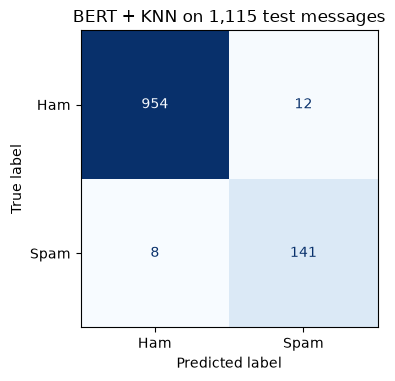

In [4]:
start = perf_counter()
part_c_pred = part_c_search.predict(test_embeddings)
part_c_predict_seconds = perf_counter() - start

part_c_precision, part_c_recall, part_c_f1, _ = precision_recall_fscore_support(
    y_test, part_c_pred, average="binary", pos_label=1, zero_division=0,
)
part_c_matrix = confusion_matrix(y_test, part_c_pred, labels=[0, 1])
part_c_results = pd.DataFrame([{
    "Representation": "BERT [CLS] embeddings",
    "Dimensions": train_embeddings.shape[1],
    "Best k": part_c_search.best_params_["n_neighbors"],
    "Test accuracy": accuracy_score(y_test, part_c_pred),
    "Spam precision": part_c_precision,
    "Spam recall": part_c_recall,
    "Spam F1": part_c_f1,
    "CV + fit (seconds)": part_c_fit_seconds,
    "Test prediction (seconds)": part_c_predict_seconds,
}])
print(part_c_results.T.to_string(header=False, float_format="{:.4f}".format))

fig, ax = plt.subplots(figsize=(4.8, 3.7), layout="constrained")
ConfusionMatrixDisplay(part_c_matrix, display_labels=["Ham", "Spam"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_title(f"BERT + KNN on {len(y_test):,} test messages")
plt.show()